Libaries are installed

In [1]:
import sys
import pandas as pd
import numpy as np
import sklearn

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Python: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
Pandas: 3.0.6
NumPy: 2.5.4
Scikit-learn: 1.9.1


 Dataset is located 

In [3]:
from pathlib import Path

dataset_path = Path("D:\\AIMO_LAMBTON_COLLEGE\\Term-3\\4. Software_tools_and_emerging_technologies_for_aiml\\Assignmnet-1\\Data\\maplefreight_delivery_delay_dataset (1).csv")

print("Dataset exists:", dataset_path.exists())
print("Dataset path:", dataset_path.resolve())

Dataset exists: True
Dataset path: D:\AIMO_LAMBTON_COLLEGE\Term-3\4. Software_tools_and_emerging_technologies_for_aiml\Assignmnet-1\Data\maplefreight_delivery_delay_dataset (1).csv


Load the dataset and calculate the rows and cols 

In [6]:
from pathlib import Path
import pandas as pd
import numpy as np

dataset_path = Path("D:\\AIMO_LAMBTON_COLLEGE\\Term-3\\4. Software_tools_and_emerging_technologies_for_aiml\\Assignmnet-1\\Data\\maplefreight_delivery_delay_dataset (1).csv")

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 6035
Number of columns: 23


Viewing the five shipments

In [7]:
df.head()

,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,...,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,...,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,...,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,...,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,...,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0


Checking the cols names

In [8]:
print("Columns in the dataset:\n")

for column in df.columns:
    print(column)

Columns in the dataset:

shipment_id
origin_city
destination_city
carrier
service_level
goods_type
customer_priority_tier
shipment_month
distance_km
weight_kg
num_stops
is_cross_border
scheduled_transit_hours
pickup_delay_minutes
driver_experience_years
vehicle_age_years
weather_condition
traffic_index
route_congestion_score
prior_late_deliveries_30d
fuel_cost_cad
actual_transit_hours
delivered_late


Checking the datatype and missing values 

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

find missing in each col

In [10]:
print("Missing values in each column:\n")
print(df.isnull().sum())

Missing values in each column:

shipment_id                    0
origin_city                    0
destination_city               0
carrier                        0
service_level                  0
goods_type                     0
customer_priority_tier         0
shipment_month                 0
distance_km                    0
weight_kg                      0
num_stops                      0
is_cross_border                0
scheduled_transit_hours        0
pickup_delay_minutes           0
driver_experience_years      210
vehicle_age_years              0
weather_condition            150
traffic_index                121
route_congestion_score         0
prior_late_deliveries_30d      0
fuel_cost_cad                240
actual_transit_hours           0
delivered_late                 0
dtype: int64


checking the late delevery 

In [11]:
if "delivered_late" in df.columns:
    print("Target column found!")
    print(df["delivered_late"].value_counts(dropna=False))
    print("\nProportion of each target class:")
    print(df["delivered_late"].value_counts(normalize=True, dropna=False).round(3))
else:
    print("The delivered_late column was not found.")
    print("Please check the column names printed above.")

Target column found!
delivered_late
0    4793
1    1242
Name: count, dtype: int64

Proportion of each target class:
delivered_late
0    0.794
1    0.206
Name: proportion, dtype: float64


In every 5 shipments 1 gets late 

Duplicate rows 

In [13]:
# Count rows that are exact duplicates
duplicate_rows = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_rows)

Exact duplicate rows: 32


Missing value

In [14]:
missing_summary = df.isnull().sum()

print("Columns with missing values:")
print(missing_summary[missing_summary > 0].sort_values(ascending=False))

Columns with missing values:
fuel_cost_cad              240
driver_experience_years    210
weather_condition          150
traffic_index              121
dtype: int64


Data type and numeric range 

In [17]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

,count,mean,std,min,25%,50%,75%,max
shipment_month,6035.0,6.543662,3.448260,1.00,4.000,7.000,10.000,12.00
distance_km,6035.0,632.192742,319.246133,80.50,398.600,571.100,804.850,2556.70
weight_kg,6035.0,6928.251135,83755.149685,30.00,496.000,827.100,1286.300,2999300.00
num_stops,6035.0,2.477051,1.707457,0.00,1.000,2.000,4.000,5.00
is_cross_border,6035.0,0.113007,0.316628,0.00,0.000,0.000,0.000,1.00
scheduled_transit_hours,6035.0,10.500388,4.758576,1.00,7.060,9.850,13.175,37.40
pickup_delay_minutes,6035.0,20.367688,30.618617,-20.00,-6.000,18.000,41.000,146.00
driver_experience_years,5825.0,6.497648,4.659277,0.20,3.200,5.400,8.600,35.00
vehicle_age_years,6035.0,5.489461,3.433676,0.10,3.000,4.800,7.200,20.00
traffic_index,5914.0,55.146365,17.592978,5.00,43.300,55.000,67.200,100.00


3. Data Quality Issue find out 

    i. Unusual shipment Weigths
    ii. negative pickup delays
    iii. data leaks

In [18]:

# 1. Check exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# 2. Display columns that contain missing values
missing_summary = df.isnull().sum()

print("\nColumns with missing values:")
print(
    missing_summary[missing_summary > 0]
    .sort_values(ascending=False)
)

# 3. Inspect unusually large shipment weights
print("\nLargest 10 shipment weights:")
print(
    df[["shipment_id", "weight_kg", "delivered_late"]]
    .sort_values("weight_kg", ascending=False)
    .head(10)
)


Exact duplicate rows: 32

Columns with missing values:
fuel_cost_cad              240
driver_experience_years    210
weather_condition          150
traffic_index              121
dtype: int64

Largest 10 shipment weights:
     shipment_id  weight_kg  delivered_late
2323  SHP-102944  2999300.0               0
846   SHP-101687  1593600.0               0
1525  SHP-102395  1554700.0               0
3284  SHP-100634  1408300.0               0
4761  SHP-104016  1389500.0               0
696   SHP-100641  1332200.0               0
4028  SHP-103017  1246100.0               0
4876  SHP-104749  1238200.0               0
4024  SHP-100891  1227100.0               1
1030  SHP-102384  1209400.0               0


duplicate shipment id

In [19]:

# Count shipment IDs that appear more than once
duplicate_ids = df[
    df["shipment_id"].duplicated(keep=False)
].sort_values("shipment_id")

print("Rows with repeated shipment IDs:", len(duplicate_ids))
print("Unique repeated shipment IDs:",
      duplicate_ids["shipment_id"].nunique())

# Display repeated records
display(duplicate_ids.head(20))


Rows with repeated shipment IDs: 70
Unique repeated shipment IDs: 35


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
1921,SHP-100018,Winnipeg MB,Sudbury ON,QuebecExpress,Economy,Fragile,Bronze,7,426.1,556.3,...,20.0,1.3,4.4,Snow,92.9,0.386,0,320.13,8.81,0
3583,SHP-100018,Winnipeg MB,Sudbury ON,QuebecExpress,Economy,Fragile,Bronze,7,426.1,556.3,...,20.0,1.3,4.4,Snow,92.9,0.386,0,320.13,8.81,0
2599,SHP-100037,Mississauga ON,Calgary AB,MapleFreight Fleet,Economy,General Freight,Silver,9,605.8,864.1,...,37.0,3.3,8.4,Clear,49.8,0.315,2,262.41,10.05,0
867,SHP-100037,Mississauga ON,Calgary AB,MapleFreight Fleet,Economy,General Freight,Silver,9,605.8,864.1,...,37.0,3.3,8.4,Clear,49.8,0.315,2,262.41,10.05,0
4115,SHP-100063,Ottawa ON,Quebec City QC,MapleFreight Fleet,Standard,Hazardous,Bronze,6,1255.7,844.8,...,48.0,4.3,11.4,Clear,41.9,0.338,1,211.74,20.18,0
5211,SHP-100063,Ottawa ON,Quebec City QC,MapleFreight Fleet,Standard,Hazardous,Bronze,6,1255.7,844.8,...,48.0,4.3,11.4,Clear,41.9,0.338,1,211.74,20.18,0
3147,SHP-100204,Toronto ON,Edmonton AB,PrairieLine,Standard,General Freight,Silver,1,945.9,1849.9,...,37.0,6.3,2.8,Rain,85.0,0.351,3,251.83,17.13,1
3991,SHP-100204,Toronto ON,Edmonton AB,PrairieLine,Standard,General Freight,Silver,1,945.9,1849.9,...,37.0,6.3,2.8,Rain,85.0,0.351,3,251.83,17.13,1
169,SHP-100457,Montreal QC,Toronto ON,PrairieLine,Economy,General Freight,Silver,8,532.1,1113.3,...,26.0,20.2,4.6,Clear,66.3,0.691,0,115.19,8.49,0
932,SHP-100457,Montreal QC,Toronto ON,PrairieLine,Economy,General Freight,Silver,8,532.1,1113.3,...,26.0,20.2,4.6,Clear,66.3,0.691,0,115.19,8.49,0


suspicious weights

In [20]:

# Summarize shipment weights
print(df["weight_kg"].describe())

# Count extremely large weights
print("\nWeights above 100,000 kg:",
      (df["weight_kg"] > 100_000).sum())

# Inspect shipments above 100,000 kg
display(
    df.loc[
        df["weight_kg"] > 100_000,
        ["shipment_id", "origin_city", "destination_city",
         "weight_kg", "distance_km", "goods_type"]
    ].sort_values("weight_kg", ascending=False).head(15)
)


count    6.035000e+03
mean     6.928251e+03
std      8.375515e+04
min      3.000000e+01
25%      4.960000e+02
50%      8.271000e+02
75%      1.286300e+03
max      2.999300e+06
Name: weight_kg, dtype: float64

Weights above 100,000 kg: 40


,shipment_id,origin_city,destination_city,weight_kg,distance_km,goods_type
2323,SHP-102944,Toronto ON,Winnipeg MB,2999300.0,349.6,Hazardous
846,SHP-101687,Ottawa ON,Edmonton AB,1593600.0,552.8,General Freight
1525,SHP-102395,Montreal QC,Edmonton AB,1554700.0,418.2,General Freight
3284,SHP-100634,Mississauga ON,Hamilton ON,1408300.0,305.2,General Freight
4761,SHP-104016,Calgary AB,Montreal QC,1389500.0,577.9,General Freight
696,SHP-100641,Mississauga ON,Quebec City QC,1332200.0,843.1,General Freight
4028,SHP-103017,Mississauga ON,Hamilton ON,1246100.0,194.0,General Freight
4876,SHP-104749,Montreal QC,Hamilton ON,1238200.0,519.3,Fragile
4024,SHP-100891,Toronto ON,Toronto ON,1227100.0,639.6,Refrigerated
1030,SHP-102384,Mississauga ON,Regina SK,1209400.0,944.6,General Freight


40 shipments were over weights

investigating the weight value 

In [21]:

large_weights = df[df["weight_kg"] > 100_000]

print("Large-weight shipments by goods type:")
print(large_weights["goods_type"].value_counts())

print("\nWeight summary by goods type:")
display(
    large_weights.groupby("goods_type")["weight_kg"]
    .agg(["count", "min", "median", "max"])
    .sort_values("count", ascending=False)
)


Large-weight shipments by goods type:
goods_type
General Freight    22
Refrigerated        7
Fragile             5
Hazardous           4
Bulk                2
Name: count, dtype: int64

Weight summary by goods type:


,count,min,median,max
goods_type,,,,
General Freight,22,170900.0,739950.0,1593600.0
Refrigerated,7,722800.0,939900.0,1227100.0
Fragile,5,380600.0,555500.0,1238200.0
Hazardous,4,811000.0,1027050.0,2999300.0
Bulk,2,449300.0,672550.0,895800.0


shipments id check 

In [22]:

duplicate_ids = df[
    df["shipment_id"].duplicated(keep=False)
].sort_values("shipment_id")

print("Rows with repeated shipment IDs:", len(duplicate_ids))
print(
    "Unique repeated shipment IDs:",
    duplicate_ids["shipment_id"].nunique()
)

display(duplicate_ids.head(20))


Rows with repeated shipment IDs: 70
Unique repeated shipment IDs: 35


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
1921,SHP-100018,Winnipeg MB,Sudbury ON,QuebecExpress,Economy,Fragile,Bronze,7,426.1,556.3,...,20.0,1.3,4.4,Snow,92.9,0.386,0,320.13,8.81,0
3583,SHP-100018,Winnipeg MB,Sudbury ON,QuebecExpress,Economy,Fragile,Bronze,7,426.1,556.3,...,20.0,1.3,4.4,Snow,92.9,0.386,0,320.13,8.81,0
2599,SHP-100037,Mississauga ON,Calgary AB,MapleFreight Fleet,Economy,General Freight,Silver,9,605.8,864.1,...,37.0,3.3,8.4,Clear,49.8,0.315,2,262.41,10.05,0
867,SHP-100037,Mississauga ON,Calgary AB,MapleFreight Fleet,Economy,General Freight,Silver,9,605.8,864.1,...,37.0,3.3,8.4,Clear,49.8,0.315,2,262.41,10.05,0
4115,SHP-100063,Ottawa ON,Quebec City QC,MapleFreight Fleet,Standard,Hazardous,Bronze,6,1255.7,844.8,...,48.0,4.3,11.4,Clear,41.9,0.338,1,211.74,20.18,0
5211,SHP-100063,Ottawa ON,Quebec City QC,MapleFreight Fleet,Standard,Hazardous,Bronze,6,1255.7,844.8,...,48.0,4.3,11.4,Clear,41.9,0.338,1,211.74,20.18,0
3147,SHP-100204,Toronto ON,Edmonton AB,PrairieLine,Standard,General Freight,Silver,1,945.9,1849.9,...,37.0,6.3,2.8,Rain,85.0,0.351,3,251.83,17.13,1
3991,SHP-100204,Toronto ON,Edmonton AB,PrairieLine,Standard,General Freight,Silver,1,945.9,1849.9,...,37.0,6.3,2.8,Rain,85.0,0.351,3,251.83,17.13,1
169,SHP-100457,Montreal QC,Toronto ON,PrairieLine,Economy,General Freight,Silver,8,532.1,1113.3,...,26.0,20.2,4.6,Clear,66.3,0.691,0,115.19,8.49,0
932,SHP-100457,Montreal QC,Toronto ON,PrairieLine,Economy,General Freight,Silver,8,532.1,1113.3,...,26.0,20.2,4.6,Clear,66.3,0.691,0,115.19,8.49,0


cheking the unit and suspicious values

In [23]:

# Show weight percentiles to understand the extreme values
print(
    df["weight_kg"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 1.00]
    )
)

# Compare the largest weights with their shipment details
display(
    df.nlargest(10, "weight_kg")[
        [
            "shipment_id",
            "goods_type",
            "weight_kg",
            "distance_km",
            "scheduled_transit_hours",
            "delivered_late"
        ]
    ]
)


0.500        827.100
0.750       1286.300
0.900       1849.500
0.950       2244.570
0.990       3360.618
0.995     535051.000
1.000    2999300.000
Name: weight_kg, dtype: float64


,shipment_id,goods_type,weight_kg,distance_km,scheduled_transit_hours,delivered_late
2323,SHP-102944,Hazardous,2999300.0,349.6,6.46,0
846,SHP-101687,General Freight,1593600.0,552.8,8.70,0
1525,SHP-102395,General Freight,1554700.0,418.2,6.32,0
3284,SHP-100634,General Freight,1408300.0,305.2,2.92,0
4761,SHP-104016,General Freight,1389500.0,577.9,8.16,0
696,SHP-100641,General Freight,1332200.0,843.1,12.60,0
4028,SHP-103017,General Freight,1246100.0,194.0,7.52,0
4876,SHP-104749,Fragile,1238200.0,519.3,6.84,0
4024,SHP-100891,Refrigerated,1227100.0,639.6,10.06,1
1030,SHP-102384,General Freight,1209400.0,944.6,13.92,0


70 rows and 35 are on repaet in shipments id 

In [24]:

# Find shipment IDs with differences across their rows
id_versions = df.groupby("shipment_id").nunique()

conflicting_ids = id_versions[
    (id_versions > 1).any(axis=1)
]

print(
    "Shipment IDs with conflicting records:",
    len(conflicting_ids)
)

if len(conflicting_ids) > 0:
    display(
        df[df["shipment_id"].isin(conflicting_ids.index)]
        .sort_values("shipment_id")
    )
else:
    print("All repeated shipment IDs have identical records.")


Shipment IDs with conflicting records: 3


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
861,SHP-101906,Toronto ON,Edmonton AB,NorthStar Carriers,Express,General Freight,Bronze,7,333.7,1002.7,...,-20.0,10.0,3.8,Storm,27.9,0.320,2,261.21,8.00,0
3030,SHP-101906,Toronto ON,Edmonton AB,NorthStar Carriers,standard,General Freight,Bronze,7,333.7,1002.7,...,-20.0,10.0,3.8,Storm,27.9,0.320,2,261.21,8.00,0
1228,SHP-102476,Toronto ON,Montreal QC,QuebecExpress,Standard,Hazardous,Silver,3,949.0,245.6,...,54.0,3.3,4.7,Storm,66.2,0.295,1,255.48,16.00,1
4033,SHP-102476,Toronto ON,Montreal QC,QuebecExpress,standard,Hazardous,Silver,3,949.0,245.6,...,54.0,3.3,4.7,Storm,66.2,0.295,1,255.48,16.00,1
441,SHP-103022,Mississauga ON,Regina SK,Contract Owner-Op,Standard,General Freight,Bronze,1,404.4,570.1,...,-10.0,7.3,3.5,Snow,64.8,0.430,3,149.40,7.53,0
4375,SHP-103022,Mississauga ON,Regina SK,Contract Owner-Op,standard,General Freight,Bronze,1,404.4,570.1,...,-10.0,7.3,3.5,Snow,64.8,0.430,3,149.40,7.53,0


Review repeated IDs and remove only confirmed orginal rows.

Create a cleaned dataset and handle missing values.

Begin EDA with charts and findings.

Move into model training, evaluation, and Slack alerts.

## Standardize text categories

In [25]:

# Create a working copy; preserve the original dataset
df_work = df.copy()

# Standardize whitespace and capitalization in text columns
text_columns = df_work.select_dtypes(
    include=["object", "str", "string"]
).columns

for col in text_columns:
    df_work[col] = (
        df_work[col]
        .str.strip()
        .str.lower()
    )

print("Text categories standardized.")
print(
    df_work.loc[
        df_work["shipment_id"].isin(
            ["SHP-101906", "SHP-102476", "SHP-103022"]
        ),
        ["shipment_id", "service_level"]
    ].sort_values("shipment_id")
)


Text categories standardized.
Empty DataFrame
Columns: [shipment_id, service_level]
Index: []


rechecking the duplicates and shipments id

In [26]:

print(
    "Exact duplicate rows after text standardization:",
    df_work.duplicated().sum()
)

id_versions = df_work.groupby("shipment_id").nunique()

conflicting_ids = id_versions[
    (id_versions > 1).any(axis=1)
]

print(
    "Shipment IDs still having conflicting records:",
    len(conflicting_ids)
)

if len(conflicting_ids) > 0:
    display(
        df_work[
            df_work["shipment_id"].isin(conflicting_ids.index)
        ].sort_values("shipment_id")
    )


Exact duplicate rows after text standardization: 34
Shipment IDs still having conflicting records: 1


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
861,shp-101906,toronto on,edmonton ab,northstar carriers,express,general freight,bronze,7,333.7,1002.7,...,-20.0,10.0,3.8,storm,27.9,0.32,2,261.21,8.0,0
3030,shp-101906,toronto on,edmonton ab,northstar carriers,standard,general freight,bronze,7,333.7,1002.7,...,-20.0,10.0,3.8,storm,27.9,0.32,2,261.21,8.0,0


chekcing the both recodes defer somewhere else 

In [27]:

# Inspect the two records for the conflicting shipment ID
shipment_check = df_work[
    df_work["shipment_id"] == "shp-101906"
]

display(shipment_check.T)

# Identify columns that differ between the two records
different_columns = [
    col for col in shipment_check.columns
    if shipment_check[col].nunique(dropna=False) > 1
]

print("Columns with conflicting values:", different_columns)


,861,3030
shipment_id,shp-101906,shp-101906
origin_city,toronto on,toronto on
destination_city,edmonton ab,edmonton ab
carrier,northstar carriers,northstar carriers
service_level,express,standard
goods_type,general freight,general freight
customer_priority_tier,bronze,bronze
shipment_month,7,7
distance_km,333.7,333.7
weight_kg,1002.7,1002.7


Columns with conflicting values: ['service_level']


removing the excat duplicate row

In [28]:

# Remove rows that are identical across every column
df_clean = df_work.drop_duplicates().copy()

print("Original working dataset shape:", df_work.shape)
print("After removing exact duplicates:", df_clean.shape)
print("Remaining exact duplicate rows:", df_clean.duplicated().sum())


Original working dataset shape: (6035, 23)
After removing exact duplicates: (6001, 23)
Remaining exact duplicate rows: 0


cheking missing value 

In [29]:

# Count missing values in each column
missing_counts = df_clean.isnull().sum()

missing_summary = missing_counts[missing_counts > 0].sort_values(
    ascending=False
)

print("Columns with missing values:")
display(missing_summary)

print("\nTotal missing cells:", df_clean.isnull().sum().sum())
print("Dataset shape:", df_clean.shape)


Columns with missing values:


fuel_cost_cad              240
driver_experience_years    210
weather_condition          150
traffic_index              120
dtype: int64


Total missing cells: 720
Dataset shape: (6001, 23)


cheking the trageted variable 

In [30]:

# Check the target distribution after duplicate removal
print(df_clean["delivered_late"].value_counts())
print("\nTarget proportions:")
display(
    df_clean["delivered_late"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nMissing target values:", df_clean["delivered_late"].isnull().sum())


delivered_late
0    4767
1    1234
Name: count, dtype: int64

Target proportions:


delivered_late
0    79.44
1    20.56
Name: proportion, dtype: float64


Missing target values: 0


Inspect missingness and data types, Check whether the late rate varies by weather

In [32]:

# Inspect data types and missing-value percentages
missing_report = pd.DataFrame({
    "data_type": df_clean.dtypes.astype(str),
    "missing_count": df_clean.isnull().sum(),
    "missing_percent": (
        df_clean.isnull().mean() * 100
    ).round(2)
})

display(
    missing_report[missing_report["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

print("\nDataset data types:")
display(df_clean.dtypes)


# Create a readable category for missing weather values
weather_check = df_clean.copy()
weather_check["weather_condition"] = (
    weather_check["weather_condition"].fillna("unknown")
)

# Calculate late-delivery rate by weather category
late_rate_by_weather = (
    weather_check.groupby("weather_condition")["delivered_late"]
    .agg(["count", "mean"])
    .rename(columns={
        "count": "shipment_count",
        "mean": "late_rate"
    })
)

late_rate_by_weather["late_rate_percent"] = (
    late_rate_by_weather["late_rate"] * 100
).round(2)

display(
    late_rate_by_weather.sort_values(
        "late_rate_percent", ascending=False
    )
)


,data_type,missing_count,missing_percent
fuel_cost_cad,float64,240,4.0
driver_experience_years,float64,210,3.5
weather_condition,str,150,2.5
traffic_index,float64,120,2.0



Dataset data types:


shipment_id                      str
origin_city                      str
destination_city                 str
carrier                          str
service_level                    str
goods_type                       str
customer_priority_tier           str
shipment_month                 int64
distance_km                  float64
weight_kg                    float64
num_stops                      int64
is_cross_border                int64
scheduled_transit_hours      float64
pickup_delay_minutes         float64
driver_experience_years      float64
vehicle_age_years            float64
weather_condition                str
traffic_index                float64
route_congestion_score       float64
prior_late_deliveries_30d      int64
fuel_cost_cad                float64
actual_transit_hours         float64
delivered_late                 int64
dtype: object

,shipment_count,late_rate,late_rate_percent
weather_condition,,,
storm,283,0.462898,46.29
snow,865,0.336416,33.64
unknown,150,0.220000,22.00
fog,419,0.210024,21.00
rain,1326,0.207391,20.74
clear,2958,0.140636,14.06


Visualize the target distribution and numeric features

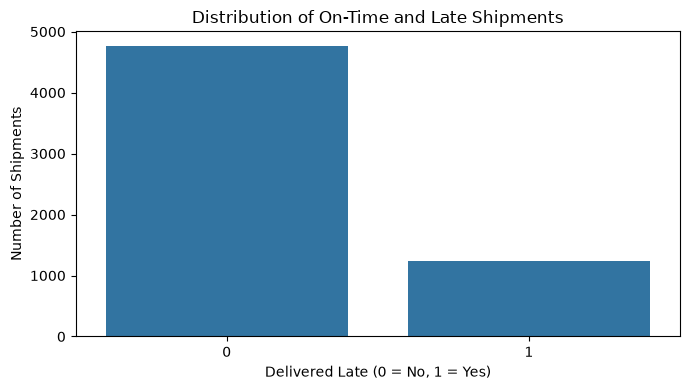

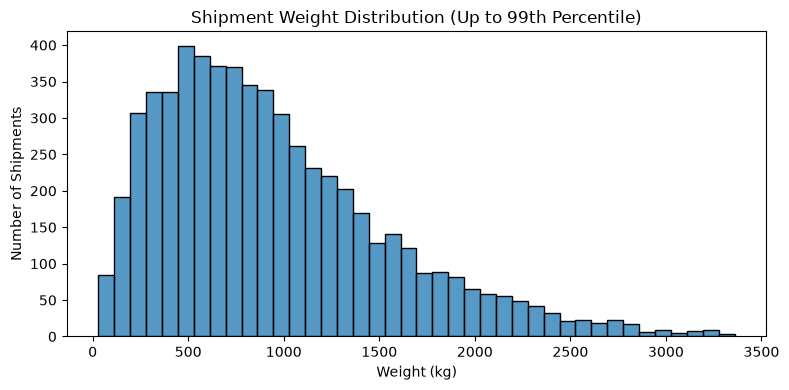

99th percentile weight: 3359.1 kg
Rows in modeling dataset: 6001


In [33]:

import matplotlib.pyplot as plt
import seaborn as sns

# Plot 1: Target distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="delivered_late")
plt.title("Distribution of On-Time and Late Shipments")
plt.xlabel("Delivered Late (0 = No, 1 = Yes)")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.show()

# Plot 2: Weight distribution, excluding extreme values
# ONLY for visualization; this does not delete any records.
weight_cap = df_clean["weight_kg"].quantile(0.99)

plt.figure(figsize=(8, 4))
sns.histplot(
    data=df_clean[df_clean["weight_kg"] <= weight_cap],
    x="weight_kg",
    bins=40
)
plt.title("Shipment Weight Distribution (Up to 99th Percentile)")
plt.xlabel("Weight (kg)")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.show()

print("99th percentile weight:", round(weight_cap, 2), "kg")
print("Rows in modeling dataset:", len(df_clean))


inspect extrem ships weight


In [34]:

# Inspect the heaviest shipments
weight_columns = [
    "shipment_id",
    "goods_type",
    "origin_city",
    "destination_city",
    "weight_kg",
    "delivered_late"
]

extreme_weights = df_clean.nlargest(15, "weight_kg")[weight_columns]

display(extreme_weights)

# Count unusually high weights
print(
    "Shipments above 100,000 kg:",
    (df_clean["weight_kg"] > 100_000).sum()
)

print(
    "Maximum shipment weight:",
    df_clean["weight_kg"].max(),
    "kg"
)


,shipment_id,goods_type,origin_city,destination_city,weight_kg,delivered_late
2323,shp-102944,hazardous,toronto on,winnipeg mb,2999300.0,0
846,shp-101687,general freight,ottawa on,edmonton ab,1593600.0,0
1525,shp-102395,general freight,montreal qc,edmonton ab,1554700.0,0
3284,shp-100634,general freight,mississauga on,hamilton on,1408300.0,0
4761,shp-104016,general freight,calgary ab,montreal qc,1389500.0,0
696,shp-100641,general freight,mississauga on,quebec city qc,1332200.0,0
4028,shp-103017,general freight,mississauga on,hamilton on,1246100.0,0
4876,shp-104749,fragile,montreal qc,hamilton on,1238200.0,0
4024,shp-100891,refrigerated,toronto on,toronto on,1227100.0,1
1030,shp-102384,general freight,mississauga on,regina sk,1209400.0,0


Shipments above 100,000 kg: 40
Maximum shipment weight: 2999300.0 kg


Ertreme Records

In [35]:

# Inspect extreme-weight shipments alongside their route and timing data
extreme_weights = df_clean.loc[
    df_clean["weight_kg"] > 100_000,
    [
        "shipment_id",
        "goods_type",
        "origin_city",
        "destination_city",
        "distance_km",
        "weight_kg",
        "scheduled_transit_hours",
        "num_stops",
        "delivered_late"
    ]
].sort_values("weight_kg", ascending=False)

display(extreme_weights)

# Check how many extreme-weight shipments have identical origin/destination
same_city = (
    df_clean["origin_city"] == df_clean["destination_city"]
)

print(
    "Extreme-weight shipments with the same origin and destination:",
    (
        (df_clean["weight_kg"] > 100_000) & same_city
    ).sum()
)


,shipment_id,goods_type,origin_city,destination_city,distance_km,weight_kg,scheduled_transit_hours,num_stops,delivered_late
2323,shp-102944,hazardous,toronto on,winnipeg mb,349.6,2999300.0,6.46,4,0
846,shp-101687,general freight,ottawa on,edmonton ab,552.8,1593600.0,8.70,3,0
1525,shp-102395,general freight,montreal qc,edmonton ab,418.2,1554700.0,6.32,1,0
3284,shp-100634,general freight,mississauga on,hamilton on,305.2,1408300.0,2.92,0,0
4761,shp-104016,general freight,calgary ab,montreal qc,577.9,1389500.0,8.16,2,0
696,shp-100641,general freight,mississauga on,quebec city qc,843.1,1332200.0,12.60,0,0
4028,shp-103017,general freight,mississauga on,hamilton on,194.0,1246100.0,7.52,5,0
4876,shp-104749,fragile,montreal qc,hamilton on,519.3,1238200.0,6.84,1,0
4024,shp-100891,refrigerated,toronto on,toronto on,639.6,1227100.0,10.06,2,1
1030,shp-102384,general freight,mississauga on,regina sk,944.6,1209400.0,13.92,4,0


Extreme-weight shipments with the same origin and destination: 2


finishing the dat quality check

In [36]:

# Summary of numeric columns
numeric_summary = df_clean.describe().T

display(
    numeric_summary[
        ["mean", "std", "min", "25%", "50%", "75%", "max"]
    ].round(2)
)

# Check columns that should contain whole numbers
for col in [
    "num_stops",
    "shipment_month",
    "is_cross_border",
    "prior_late_deliveries_30d",
    "delivered_late"
]:
    fractional_count = (
        df_clean[col].dropna().mod(1).ne(0).sum()
    )
    print(f"{col}: {fractional_count} fractional values")

# Check suspicious ranges
print(
    "\nNon-positive shipment distances:",
    (df_clean["distance_km"] <= 0).sum()
)
print(
    "Non-positive scheduled transit hours:",
    (df_clean["scheduled_transit_hours"] <= 0).sum()
)
print(
    "Negative shipment weights:",
    (df_clean["weight_kg"] < 0).sum()
)


,mean,std,min,25%,50%,75%,max
shipment_month,6.54,3.45,1.00,4.00,7.00,10.00,12.00
distance_km,632.12,319.38,80.50,398.40,571.10,804.50,2556.70
weight_kg,6961.40,83990.94,30.00,496.00,827.10,1286.40,2999300.00
num_stops,2.47,1.71,0.00,1.00,2.00,4.00,5.00
is_cross_border,0.11,0.32,0.00,0.00,0.00,0.00,1.00
scheduled_transit_hours,10.50,4.76,1.00,7.06,9.83,13.17,37.40
pickup_delay_minutes,20.35,30.60,-20.00,-6.00,18.00,41.00,146.00
driver_experience_years,6.51,4.66,0.20,3.20,5.40,8.70,35.00
vehicle_age_years,5.49,3.44,0.10,3.00,4.80,7.20,20.00
traffic_index,55.14,17.60,5.00,43.30,55.00,67.20,100.00


num_stops: 0 fractional values
shipment_month: 0 fractional values
is_cross_border: 0 fractional values
prior_late_deliveries_30d: 0 fractional values
delivered_late: 0 fractional values

Non-positive shipment distances: 0
Non-positive scheduled transit hours: 0
Negative shipment weights: 0


Separate the target, features, and shipment IDs

In [37]:

# Preserve shipment IDs for later Slack alerts
shipment_ids = df_clean["shipment_id"].copy()

# Define the target
y = df_clean["delivered_late"].copy()

# Remove columns that must not be model features
X = df_clean.drop(
    columns=[
        "shipment_id",
        "actual_transit_hours",
        "delivered_late"
    ]
).copy()

print("Feature dataset shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts())

print("\nFeature columns:")
print(X.columns.tolist())


Feature dataset shape: (6001, 20)
Target shape: (6001,)

Target distribution:


delivered_late
0    4767
1    1234
Name: count, dtype: int64


Feature columns:
['origin_city', 'destination_city', 'carrier', 'service_level', 'goods_type', 'customer_priority_tier', 'shipment_month', 'distance_km', 'weight_kg', 'num_stops', 'is_cross_border', 'scheduled_transit_hours', 'pickup_delay_minutes', 'driver_experience_years', 'vehicle_age_years', 'weather_condition', 'traffic_index', 'route_congestion_score', 'prior_late_deliveries_30d', 'fuel_cost_cad']


Split the data into training and test sets

In [38]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target proportions (%):")
display((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target proportions (%):")
display((y_test.value_counts(normalize=True) * 100).round(2))


Training features: (4800, 20)
Testing features: (1201, 20)

Training target proportions (%):


delivered_late
0    79.44
1    20.56
Name: proportion, dtype: float64


Testing target proportions (%):


delivered_late
0    79.43
1    20.57
Name: proportion, dtype: float64

cartrigeous cols

In [39]:

import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Identify categorical and numeric feature columns
categorical_columns = X_train.select_dtypes(
    include=["object", "str", "string"]
).columns.tolist()

numeric_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_columns)
print("Numeric columns:", numeric_columns)

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Create baseline model
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Preprocessing pipeline and baseline model created.")


Categorical columns: ['origin_city', 'destination_city', 'carrier', 'service_level', 'goods_type', 'customer_priority_tier', 'weather_condition']
Numeric columns: ['shipment_month', 'distance_km', 'weight_kg', 'num_stops', 'is_cross_border', 'scheduled_transit_hours', 'pickup_delay_minutes', 'driver_experience_years', 'vehicle_age_years', 'traffic_index', 'route_congestion_score', 'prior_late_deliveries_30d', 'fuel_cost_cad']
Preprocessing pipeline and baseline model created.


training my first model 

In [40]:

# Train using training data only
baseline_model.fit(X_train, y_train)

# Predict labels and probabilities on the held-out test set
y_pred = baseline_model.predict(X_test)
y_proba = baseline_model.predict_proba(X_test)[:, 1]

print("Classification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["On time", "Late"]
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1-score:", round(f1_score(y_test, y_pred), 3))
print("PR-AUC / Average precision:",
      round(average_precision_score(y_test, y_proba), 3))


Classification report:
              precision    recall  f1-score   support

     On time       0.92      0.74      0.82       954
        Late       0.43      0.74      0.54       247

    accuracy                           0.74      1201
   macro avg       0.67      0.74      0.68      1201
weighted avg       0.82      0.74      0.76      1201

Confusion matrix:
[[709 245]
 [ 65 182]]
Precision: 0.426
Recall: 0.737
F1-score: 0.54
PR-AUC / Average precision: 0.598


Train a Random Forest model

In [41]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    f1_score
)

# Build the Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train on training data only
rf_model.fit(X_train, y_train)

# Evaluate on the held-out test set
rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest classification report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["On time", "Late"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, rf_pred))

print("Late-class F1:", round(
    f1_score(y_test, rf_pred), 3
))

print("Average precision:", round(
    average_precision_score(y_test, rf_proba), 3
))


Random Forest classification report:
              precision    recall  f1-score   support

     On time       0.87      0.91      0.89       954
        Late       0.56      0.46      0.51       247

    accuracy                           0.82      1201
   macro avg       0.72      0.68      0.70      1201
weighted avg       0.80      0.82      0.81      1201

Confusion matrix:
[[866  88]
 [133 114]]
Late-class F1: 0.508
Average precision: 0.544


comparing my both models

In [42]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    average_precision_score
)

model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Late Precision": precision_score(y_test, y_pred, zero_division=0),
        "Late Recall": recall_score(y_test, y_pred, zero_division=0),
        "Late F1": f1_score(y_test, y_pred, zero_division=0),
        "Average Precision": average_precision_score(y_test, y_proba)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Late Precision": precision_score(y_test, rf_pred, zero_division=0),
        "Late Recall": recall_score(y_test, rf_pred, zero_division=0),
        "Late F1": f1_score(y_test, rf_pred, zero_division=0),
        "Average Precision": average_precision_score(y_test, rf_proba)
    }
])

display(model_comparison.round(3))


,Model,Accuracy,Late Precision,Late Recall,Late F1,Average Precision
0,Logistic Regression,0.742,0.426,0.737,0.540,0.598
1,Random Forest,0.816,0.564,0.462,0.508,0.544


Logistic Regression

In [43]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Compare different thresholds for identifying late shipments
threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    threshold_pred = (y_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Late Precision": precision_score(
            y_test, threshold_pred, zero_division=0
        ),
        "Late Recall": recall_score(
            y_test, threshold_pred, zero_division=0
        ),
        "Late F1": f1_score(
            y_test, threshold_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))


,Threshold,Late Precision,Late Recall,Late F1
0,0.30,0.320,0.895,0.472
1,0.35,0.344,0.858,0.491
2,0.40,0.367,0.818,0.507
3,0.45,0.401,0.777,0.529
4,0.50,0.426,0.737,0.540
5,0.55,0.468,0.709,0.564
6,0.60,0.513,0.652,0.574


checking which feature infulce the predection 

In [44]:

import pandas as pd
import numpy as np

# Get feature names after preprocessing
feature_names = (
    baseline_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Logistic Regression coefficients
coefficients = (
    baseline_model.named_steps["classifier"].coef_[0]
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute Importance": np.abs(coefficients)
})

# Show the strongest positive and negative associations
print("Features associated with higher predicted delay:")
display(
    feature_importance
    .sort_values("Coefficient", ascending=False)
    .head(10)
    .round(3)
)

print("Features associated with lower predicted delay:")
display(
    feature_importance
    .sort_values("Coefficient", ascending=True)
    .head(10)
    .round(3)
)


Features associated with higher predicted delay:


,Feature,Coefficient,Absolute Importance
50,categorical__weather_condition_storm,1.470,1.470
30,categorical__carrier_contract owner-op,0.788,0.788
1,numeric__distance_km,0.604,0.604
9,numeric__traffic_index,0.544,0.544
35,categorical__service_level_economy,0.514,0.514
3,numeric__num_stops,0.503,0.503
49,categorical__weather_condition_snow,0.476,0.476
6,numeric__pickup_delay_minutes,0.418,0.418
11,numeric__prior_late_deliveries_30d,0.336,0.336
10,numeric__route_congestion_score,0.304,0.304


Features associated with lower predicted delay:


,Feature,Coefficient,Absolute Importance
46,categorical__weather_condition_clear,-0.955,0.955
31,categorical__carrier_maplefreight fleet,-0.880,0.880
47,categorical__weather_condition_fog,-0.488,0.488
36,categorical__service_level_express,-0.438,0.438
48,categorical__weather_condition_rain,-0.409,0.409
7,numeric__driver_experience_years,-0.298,0.298
25,categorical__destination_city_quebec city qc,-0.178,0.178
13,categorical__origin_city_calgary ab,-0.109,0.109
38,categorical__goods_type_bulk,-0.109,0.109
0,numeric__shipment_month,-0.106,0.106


valaditation set 

In [45]:

from sklearn.model_selection import train_test_split

# Keep the existing test set untouched.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training rows:", len(X_fit))
print("Validation rows:", len(X_val))
print("Final test rows:", len(X_test))

print("\nLate-delivery rate:")
print("Training:", round(y_fit.mean(), 3))
print("Validation:", round(y_val.mean(), 3))
print("Test:", round(y_test.mean(), 3))


Model training rows: 3840
Validation rows: 960
Final test rows: 1201

Late-delivery rate:
Training: 0.206
Validation: 0.205
Test: 0.206


In [46]:

from sklearn.base import clone
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    f1_score
)

# Create a fresh model with the same preprocessing
validation_model = clone(baseline_model)

# Train only on the fitting subset
validation_model.fit(X_fit, y_fit)

# Predict on validation data
val_pred = validation_model.predict(X_val)
val_proba = validation_model.predict_proba(X_val)[:, 1]

print("Validation classification report:")
print(classification_report(
    y_val,
    val_pred,
    target_names=["On time", "Late"],
    zero_division=0
))

print("Validation confusion matrix:")
print(confusion_matrix(y_val, val_pred))

print("Late F1:", round(f1_score(y_val, val_pred), 3))
print("Average precision:", round(
    average_precision_score(y_val, val_proba), 3
))


Validation classification report:
              precision    recall  f1-score   support

     On time       0.90      0.75      0.81       763
        Late       0.40      0.66      0.50       197

    accuracy                           0.73       960
   macro avg       0.65      0.71      0.66       960
weighted avg       0.80      0.73      0.75       960

Validation confusion matrix:
[[570 193]
 [ 66 131]]
Late F1: 0.503
Average precision: 0.557


validation data 

In [47]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    pred = (val_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Late Precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "Late Recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "Late F1": f1_score(
            y_val, pred, zero_division=0
        )
    })

validation_thresholds = pd.DataFrame(threshold_results)
display(validation_thresholds.round(3))


,Threshold,Late Precision,Late Recall,Late F1
0,0.30,0.324,0.883,0.474
1,0.35,0.343,0.838,0.487
2,0.40,0.357,0.761,0.486
3,0.45,0.377,0.721,0.495
4,0.50,0.404,0.665,0.503
5,0.55,0.421,0.594,0.493
6,0.60,0.446,0.548,0.492


threshold

In [48]:

# Select the threshold with the highest validation F1
best_row = validation_thresholds.loc[
    validation_thresholds["Late F1"].idxmax()
]

best_threshold = float(best_row["Threshold"])

print("Selected threshold:", best_threshold)
print("Validation Late Precision:", best_row["Late Precision"])
print("Validation Late Recall:", best_row["Late Recall"])
print("Validation Late F1:", best_row["Late F1"])


Selected threshold: 0.5
Validation Late Precision: 0.404320987654321
Validation Late Recall: 0.6649746192893401
Validation Late F1: 0.5028790786948176


evaluation on the untouched test set

In [49]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    f1_score
)

# Predict probabilities on the final test set
test_proba = validation_model.predict_proba(X_test)[:, 1]

# Apply the selected validation threshold
test_pred = (test_proba >= best_threshold).astype(int)

print("Final test classification report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["On time", "Late"],
    zero_division=0
))

print("Final test confusion matrix:")
print(confusion_matrix(y_test, test_pred))

print("Final test Late F1:",
      round(f1_score(y_test, test_pred), 3))

print("Final test Average Precision:",
      round(average_precision_score(y_test, test_proba), 3))


Final test classification report:
              precision    recall  f1-score   support

     On time       0.92      0.75      0.83       954
        Late       0.44      0.76      0.55       247

    accuracy                           0.75      1201
   macro avg       0.68      0.75      0.69      1201
weighted avg       0.82      0.75      0.77      1201

Final test confusion matrix:
[[713 241]
 [ 60 187]]
Final test Late F1: 0.554
Final test Average Precision: 0.601


In [50]:
#predection function
import pandas as pd

ALERT_THRESHOLD = best_threshold

def predict_delivery_delays(shipment_data, model=validation_model):
    """
    Predict potential delivery delays for new shipment records.

    shipment_id is retained for identification but excluded
    from model features.
    """
    shipment_data = shipment_data.copy()

    if "shipment_id" not in shipment_data.columns:
        raise ValueError("Input data must contain shipment_id.")

    shipment_ids = shipment_data["shipment_id"].copy()

    # Remove identifiers and information unavailable before delivery.
    model_features = shipment_data.drop(
        columns=[
            "shipment_id",
            "actual_transit_hours",
            "delivered_late"
        ],
        errors="ignore"
    )

    # Align columns with the model's training features.
    expected_columns = X_fit.columns
    missing_columns = set(expected_columns) - set(model_features.columns)
    extra_columns = set(model_features.columns) - set(expected_columns)

    if missing_columns or extra_columns:
        raise ValueError(
            f"Input feature mismatch. Missing: {sorted(missing_columns)}; "
            f"unexpected: {sorted(extra_columns)}"
        )

    model_features = model_features[expected_columns]

    probabilities = model.predict_proba(model_features)[:, 1]

    results = pd.DataFrame({
        "shipment_id": shipment_ids.to_numpy(),
        "late_probability": probabilities,
        "predicted_late": (probabilities >= ALERT_THRESHOLD).astype(int)
    })

    return results.sort_values(
        "late_probability", ascending=False
    ).reset_index(drop=True)


print("Prediction function created successfully.")
print("Alert threshold:", ALERT_THRESHOLD)


Prediction function created successfully.
Alert threshold: 0.5


In [52]:
#test function

# Create one sample from the existing feature data.
# This checks the prediction workflow, not real-world performance.
sample_shipment = X_val.iloc[[0]].copy()
sample_shipment.insert(
    0,
    "shipment_id",
    ["demo_shipment_001"]
)

sample_result = predict_delivery_delays(sample_shipment)
display(sample_result)


,shipment_id,late_probability,predicted_late
0,demo_shipment_001,0.261196,0


Slack Alert

In [53]:

def generate_slack_alert(prediction_result):
    """Create Slack-style alerts for shipments predicted to be late."""
    late_shipments = prediction_result[
        prediction_result["late_probability"] >= ALERT_THRESHOLD
    ]

    if late_shipments.empty:
        print("No late-delivery alerts. All shipments are below the threshold.")
        return

    for _, shipment in late_shipments.iterrows():
        message = (
            f"🚨 DELIVERY DELAY ALERT\n"
            f"Shipment ID: {shipment['shipment_id']}\n"
            f"Late probability: {shipment['late_probability']:.1%}\n"
            f"Alert threshold: {ALERT_THRESHOLD:.0%}\n"
            f"Predicted late: Yes"
        )
        print(message)
        print("-" * 40)


# Test using the prediction result you already generated
generate_slack_alert(sample_result)


No late-delivery alerts. All shipments are below the threshold.


Run this test

In [54]:

import pandas as pd

test_alert = pd.DataFrame({
    "shipment_id": ["TEST_SHIPMENT_001"],
    "late_probability": [0.85],
    "predicted_late": [1]
})

generate_slack_alert(test_alert)


🚨 DELIVERY DELAY ALERT
Shipment ID: TEST_SHIPMENT_001
Late probability: 85.0%
Alert threshold: 50%
Predicted late: Yes
----------------------------------------


In [1]:

%pip install python-dotenv requests


  Using cached python_dotenv-1.2.4-py3-none-any.whl.metadata (29 kB)
Using cached python_dotenv-1.2.4-py3-none-any.whl (23 kB)
Note: you may need to restart the kernel to use updated packages.


checking slack connection

In [13]:

import os
from pathlib import Path
import requests
from dotenv import load_dotenv

env_path = Path(
    r"D:\AIMO_LAMBTON_COLLEGE\Term-3\4. Software_tools_and_emerging_technologies_for_aiml\Assignmnet-1\.env"
)

load_dotenv(env_path, override=True)

url = os.getenv("SLACK_WEBHOOK_URL")

if not url:
    raise ValueError(
        f"Webhook not found. Add SLACK_WEBHOOK_URL to: {env_path}"
    )

response = requests.post(
    url,
    json={
        "text": "Test: MapleFreight delay alerts are connected."
    },
    timeout=15,
)

if response.status_code == 200 and response.text == "ok":
    print("SUCCESS: Slack test message sent!")
else:
    print("Slack error:", response.status_code, response.text)
    response.raise_for_status()


SUCCESS: Slack test message sent!
